# **Proceso segmentacion**

## **Importar librerias**

In [1]:
import sys
!{sys.executable} -m pip install scikit-learn-extra

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 15.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2154553 sha256=53ab519e6c1ce11fcd743038337d83a5e0915622cd382846f900a29d534d1c8b
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [2]:
!pip install scikit-learn-extra

In [3]:
from sklearn_extra.cluster import KMedoids

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import seaborn as sns


from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    fcluster
)

from scipy.spatial.distance import pdist


In [6]:
base_clientes = pd.read_csv('/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/base_clientes.csv')
base_clientes.head()

,cod_cliente_alicorp_actual,nom_cliente_alicorp_actual,cod_grupo_precio_alicorp,venta_promedio_mensual,mix_cuidado_hogar,mix_abarrotes,mix_golosinas,mix_cuidado_personal,mix_panetones,frecuencia_promedio_compra
0,5003998,MARIANA CORTES MORAL,OT,-162.710000,0.000000,0.0,0.0,0.0,0,0.000000
1,5017346,ANA PATRICIA TAVARA CUEVA,OT,-2408.560000,0.000000,0.0,0.0,0.0,0,0.000000
2,1000000003,EMPRESA DE TRANSPORTES MI BEATRIZ,OT,1103.008571,1.666667,2.0,2.0,0.0,0,1.428571
3,1000000031,BANCO DE ALIMENTOS PERU,OT,0.000000,0.000000,0.0,0.0,0.0,0,3.250000
4,1000000041,TRANS. PERUANOS NUEVA ESPERANZA S.A,OT,3894.975000,1.000000,2.0,5.0,0.0,0,1.000000


In [7]:
base_clientes = base_clientes[base_clientes["cod_grupo_precio_alicorp"] == 'D4']
base_clientes = base_clientes[base_clientes["venta_promedio_mensual"] >0]

In [8]:
base_clientes.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 25 to 815
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   cod_cliente_alicorp_actual  150 non-null    int64  
 1   nom_cliente_alicorp_actual  150 non-null    object 
 2   cod_grupo_precio_alicorp    150 non-null    object 
 3   venta_promedio_mensual      150 non-null    float64
 4   mix_cuidado_hogar           150 non-null    float64
 5   mix_abarrotes               150 non-null    float64
 6   mix_golosinas               150 non-null    float64
 7   mix_cuidado_personal        150 non-null    float64
 8   mix_panetones               150 non-null    int64  
 9   frecuencia_promedio_compra  150 non-null    float64
dtypes: float64(6), int64(2), object(2)
memory usage: 12.9+ KB


In [9]:
## Eliminamos outliers

Q1 = base_clientes['venta_promedio_mensual'].quantile(0.25)
Q3 = base_clientes['venta_promedio_mensual'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = base_clientes[
    (base_clientes['venta_promedio_mensual'] < limite_inferior) |
    (base_clientes['venta_promedio_mensual'] > limite_superior)
]

In [10]:
base_clientes = base_clientes[base_clientes["venta_promedio_mensual"]<=limite_superior]

In [11]:
base_clientes.info()

<class 'pandas.core.frame.DataFrame'>
Index: 141 entries, 25 to 815
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   cod_cliente_alicorp_actual  141 non-null    int64  
 1   nom_cliente_alicorp_actual  141 non-null    object 
 2   cod_grupo_precio_alicorp    141 non-null    object 
 3   venta_promedio_mensual      141 non-null    float64
 4   mix_cuidado_hogar           141 non-null    float64
 5   mix_abarrotes               141 non-null    float64
 6   mix_golosinas               141 non-null    float64
 7   mix_cuidado_personal        141 non-null    float64
 8   mix_panetones               141 non-null    int64  
 9   frecuencia_promedio_compra  141 non-null    float64
dtypes: float64(6), int64(2), object(2)
memory usage: 12.1+ KB


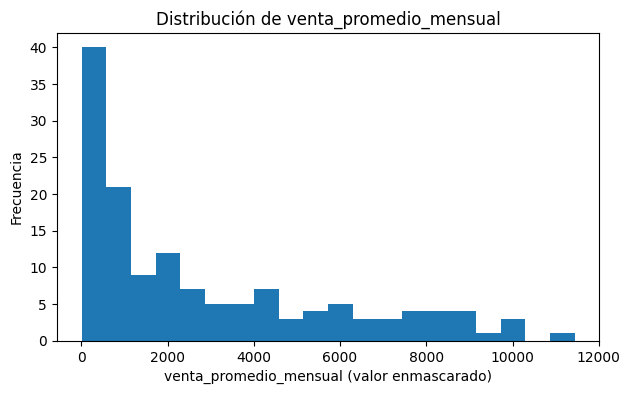

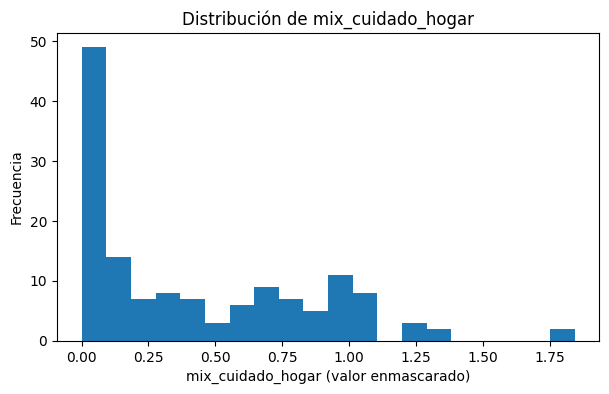

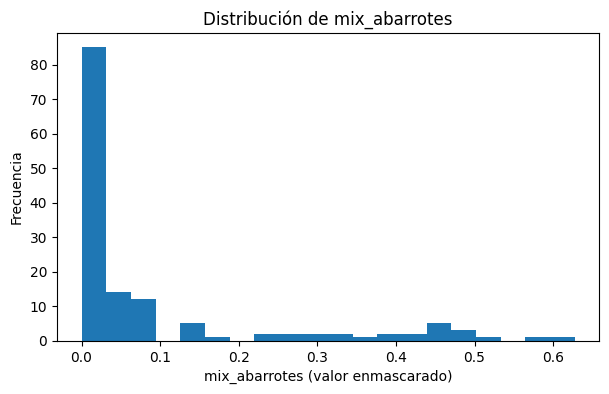

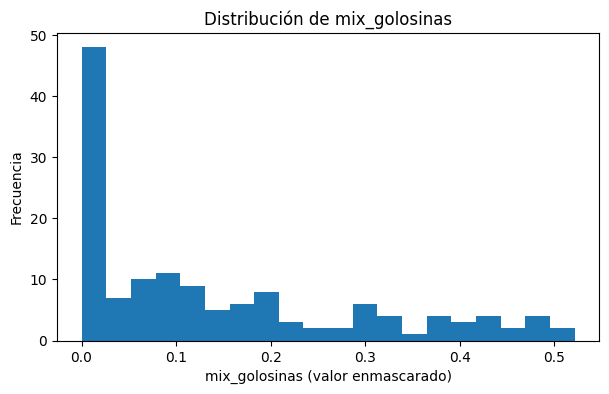

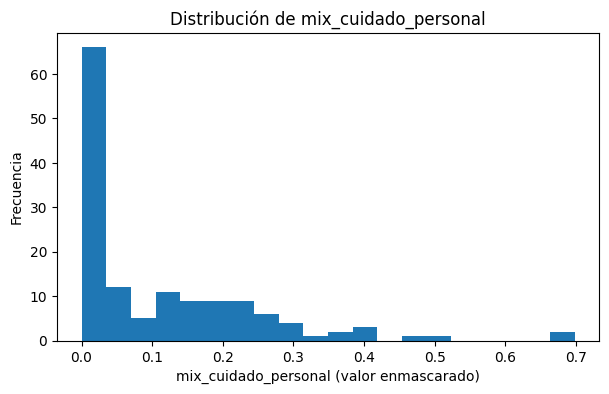

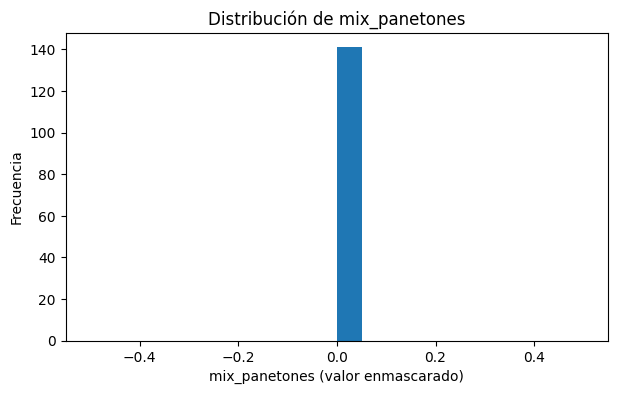

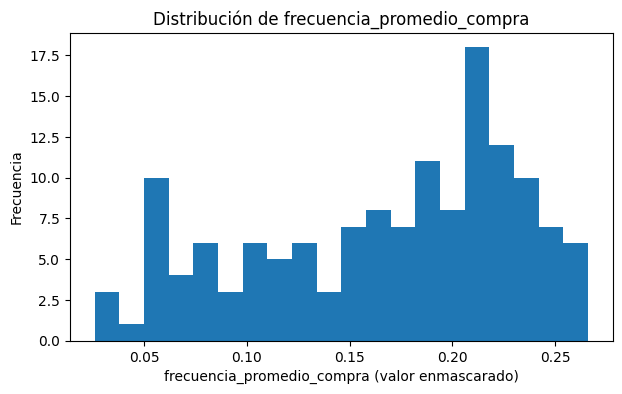

In [12]:
columnas = [
    'venta_promedio_mensual',
    'mix_cuidado_hogar',
    'mix_abarrotes',
    'mix_golosinas',
    'mix_cuidado_personal',
    'mix_panetones',
    'frecuencia_promedio_compra'
]

factor = 0.01

for columna in columnas:
    plt.figure(figsize=(7, 4))

    datos = base_clientes[columna].dropna() * factor

    plt.hist(datos, bins=20)

    plt.xlabel(f'{columna} (valor enmascarado)')
    plt.ylabel('Frecuencia')
    plt.title(f'Distribución de {columna}')

    plt.show()
    print("")
    print("")
    print("")

In [13]:
base_clientes.describe()

,cod_cliente_alicorp_actual,venta_promedio_mensual,mix_cuidado_hogar,mix_abarrotes,mix_golosinas,mix_cuidado_personal,mix_panetones,frecuencia_promedio_compra
count,1.410000e+02,1.410000e+02,141.000000,141.000000,141.000000,141.000000,141.0,141.000000
mean,1.000024e+09,2.858988e+05,42.264762,8.837723,14.015786,10.761868,0.0,16.678414
std,1.511328e+04,2.933064e+05,43.673051,15.357105,15.258677,13.945552,0.0,6.449690
min,1.000000e+09,7.038067e+02,0.000000,0.000000,0.000000,0.000000,0.0,2.600000
25%,1.000010e+09,4.407636e+04,0.000000,0.000000,0.000000,0.000000,0.0,11.400000
50%,1.000019e+09,1.722737e+05,28.428571,1.000000,9.125000,4.666667,0.0,18.416667
75%,1.000031e+09,4.443752e+05,78.500000,8.000000,23.250000,18.833333,0.0,21.666667
max,1.000055e+09,1.144120e+06,184.416667,62.750000,52.166667,69.833333,0.0,26.583333


## **Metodo KMEANS**

Valores nulos:
venta_promedio_mensual        0
mix_cuidado_hogar             0
mix_abarrotes                 0
mix_golosinas                 0
mix_cuidado_personal          0
frecuencia_promedio_compra    0
dtype: int64
    k     inercia  silhouette
0   2  460.148957    0.433794
1   3  344.429478    0.409780
2   4  277.983727    0.345684
3   5  238.646142    0.340821
4   6  209.617529    0.333234
5   7  189.771500    0.337216
6   8  174.198177    0.329934
7   9  163.023014    0.350715
8  10  149.519581    0.329994


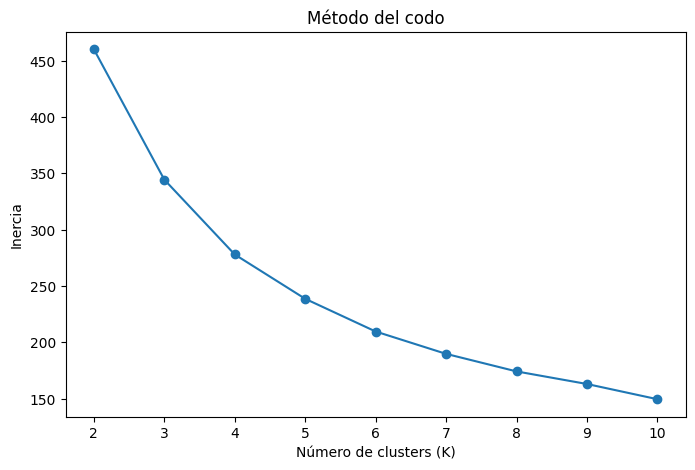

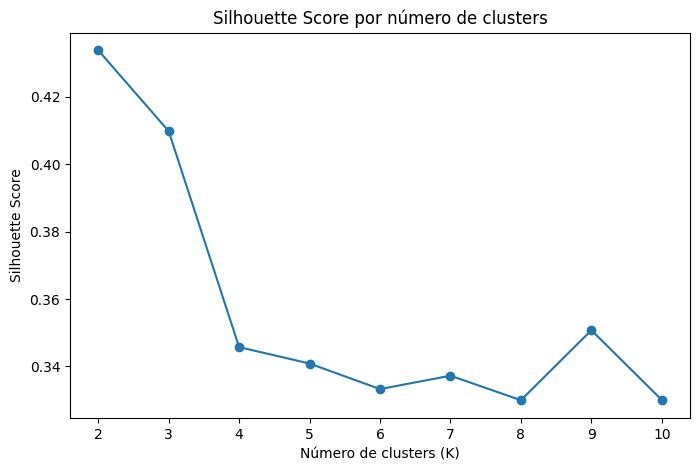

cluster
0    31
1    24
2    54
3    32
Name: count, dtype: int64
         venta_promedio_mensual  mix_cuidado_hogar  mix_abarrotes  \
cluster                                                             
0                     453063.95              82.85           3.79   
1                     680874.97              93.65          39.13   
2                      56871.74               8.38           1.39   
3                     214208.47              21.59           3.57   

         mix_golosinas  mix_cuidado_personal  frecuencia_promedio_compra  
cluster                                                                   
0                 3.35                 26.70                       21.35  
1                30.36                 21.22                       23.42  
2                 6.53                  1.55                        9.94  
3                24.73                  3.03                       18.46  
         clientes  % clientes
cluster                      
0        

In [14]:
# ============================================================
# 3. VARIABLES PARA LA SEGMENTACIÓN
# ============================================================

variables_cluster = [
    'venta_promedio_mensual',
    'mix_cuidado_hogar',
    'mix_abarrotes',
    'mix_golosinas',
    'mix_cuidado_personal',
    #'mix_panetones',
    'frecuencia_promedio_compra'
]

X = base_clientes[variables_cluster].copy()


# ============================================================
# 4. LIMPIEZA DE DATOS
# ============================================================

# Convertir variables a numéricas
for col in variables_cluster:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# Revisar nulos
print("Valores nulos:")
print(X.isnull().sum())

# Reemplazar infinitos por NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Eliminar registros con datos faltantes
mask_validos = X.notnull().all(axis=1)

df_modelo = base_clientes.loc[mask_validos].copy()
X = X.loc[mask_validos].copy()


# ============================================================
# 5. ESTANDARIZACIÓN
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_cluster,
    index=X.index
)


# ============================================================
# 6. PROBAR DIFERENTES NÚMEROS DE CLUSTERS
# ============================================================

resultados = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=20,
        random_state=42
    )

    clusters = kmeans.fit_predict(X_scaled)

    silhouette = silhouette_score(
        X_scaled,
        clusters
    )

    resultados.append({
        'k': k,
        'inercia': kmeans.inertia_,
        'silhouette': silhouette
    })

resultados = pd.DataFrame(resultados)

print(resultados)


# ============================================================
# 7. GRÁFICO DEL MÉTODO DEL CODO
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    resultados['k'],
    resultados['inercia'],
    marker='o'
)

plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia')
plt.title('Método del codo')

plt.xticks(range(2, 11))

plt.show()


# ============================================================
# 8. GRÁFICO DEL SILHOUETTE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    resultados['k'],
    resultados['silhouette'],
    marker='o'
)

plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score por número de clusters')

plt.xticks(range(2, 11))

plt.show()


# ============================================================
# 9. ELEGIR K
# ============================================================

# Ejemplo:
# Cambia este valor después de analizar los gráficos

k_final = 4

kmeans_final = KMeans(
    n_clusters=k_final,
    init='k-means++',
    n_init=20,
    random_state=42
)

clusters_final = kmeans_final.fit_predict(X_scaled)


# ============================================================
# 10. ASIGNAR CLUSTER A CADA CLIENTE
# ============================================================

df_modelo['cluster'] = clusters_final

# Revisar cantidad de clientes por cluster
print(
    df_modelo['cluster']
    .value_counts()
    .sort_index()
)


# ============================================================
# 11. PERFIL DE CADA CLUSTER
# ============================================================

perfil_clusters = (
    df_modelo
    .groupby('cluster')[variables_cluster]
    .mean()
    .round(2)
)

print(perfil_clusters)


# ============================================================
# 12. TAMAÑO DE CADA SEGMENTO
# ============================================================

tamano_clusters = (
    df_modelo['cluster']
    .value_counts()
    .sort_index()
    .to_frame('clientes')
)

tamano_clusters['% clientes'] = (
    tamano_clusters['clientes']
    / len(df_modelo)
    * 100
).round(2)

print(tamano_clusters)


# ============================================================
# 13. CENTROIDES EN ESCALA ORIGINAL
# ============================================================

centroides = pd.DataFrame(
    scaler.inverse_transform(kmeans_final.cluster_centers_),
    columns=variables_cluster
)

centroides.index.name = 'cluster'

print(centroides.round(2))


# ============================================================
# 14. EXPORTAR RESULTADOS
# ============================================================

df_modelo.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/clientes_segmentados_kmeans.xlsx",
    index=False
)

perfil_clusters.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/perfil_clusters.xlsx"
)

print("Proceso terminado.")

Valores nulos:
venta_promedio_mensual        0
mix_cuidado_hogar             0
mix_abarrotes                 0
mix_golosinas                 0
mix_cuidado_personal          0
frecuencia_promedio_compra    0
dtype: int64

Resultados de evaluación:
    k   inercia  silhouette  calinski_harabasz  davies_bouldin
0   2  460.1490      0.4338           116.5564          1.0266
1   3  344.4295      0.4098           100.4803          1.0383
2   4  277.9837      0.3457            93.3127          1.0920
3   5  238.6461      0.3408            86.5299          1.0317
4   6  209.6175      0.3332            81.9699          1.1512
5   7  189.7715      0.3372            77.2285          1.1945
6   8  174.1982      0.3299            73.2742          1.0613
7   9  163.0230      0.3507            69.1259          1.0536
8  10  149.5196      0.3300            67.8016          0.9918


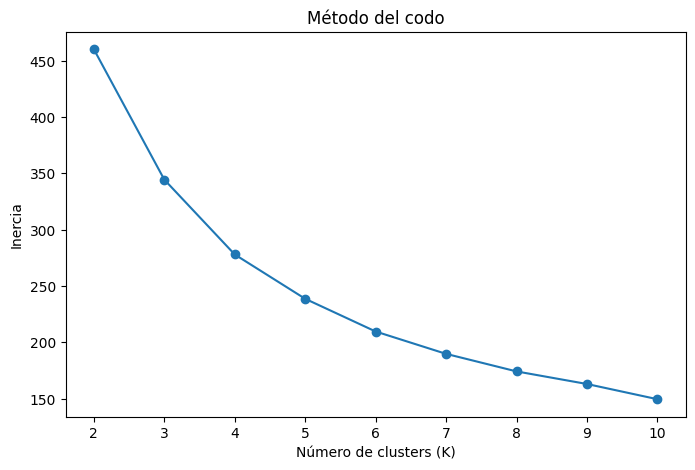

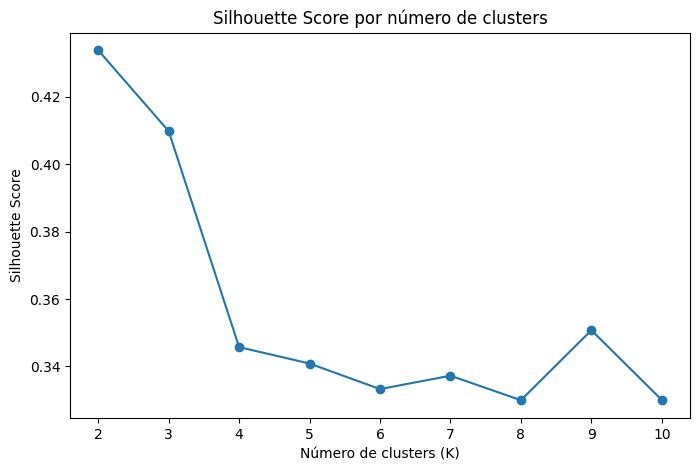

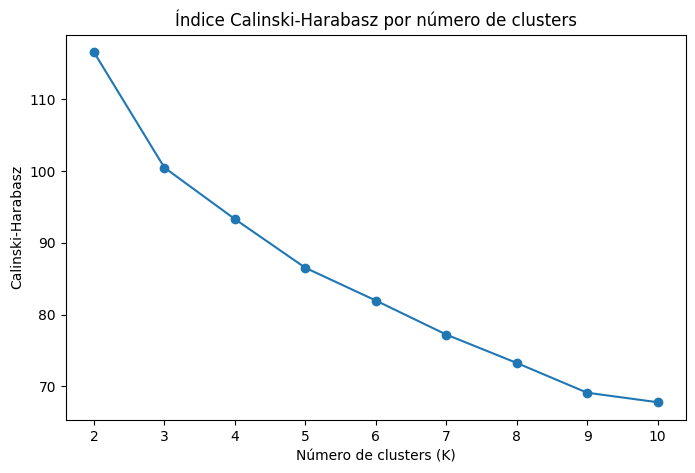

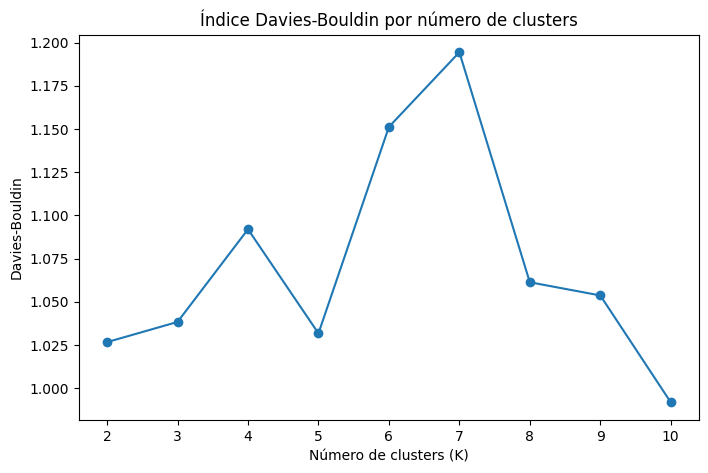


MEJORES RESULTADOS
Mejor K según Silhouette: K=2 (Score=0.4338)
Mejor K según Calinski-Harabasz: K=2 (Score=116.5564)
Mejor K según Davies-Bouldin: K=10 (Score=0.9918)

Cantidad de clientes por cluster:
cluster
0    31
1    24
2    54
3    32
Name: count, dtype: int64

Perfil de los clusters:
         venta_promedio_mensual  mix_cuidado_hogar  mix_abarrotes  \
cluster                                                             
0                     453063.95              82.85           3.79   
1                     680874.97              93.65          39.13   
2                      56871.74               8.38           1.39   
3                     214208.47              21.59           3.57   

         mix_golosinas  mix_cuidado_personal  frecuencia_promedio_compra  
cluster                                                                   
0                 3.35                 26.70                       21.35  
1                30.36                 21.22                     

In [15]:
# ============================================================
# 3. VARIABLES PARA LA SEGMENTACIÓN
# ============================================================

variables_cluster = [
    'venta_promedio_mensual',
    'mix_cuidado_hogar',
    'mix_abarrotes',
    'mix_golosinas',
    'mix_cuidado_personal',
    #'mix_panetones',
    'frecuencia_promedio_compra'
]

X = base_clientes[variables_cluster].copy()


# ============================================================
# 4. LIMPIEZA DE DATOS
# ============================================================

# Convertir variables a numéricas
for col in variables_cluster:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# Revisar nulos
print("Valores nulos:")
print(X.isnull().sum())

# Reemplazar infinitos por NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Eliminar registros con datos faltantes
mask_validos = X.notnull().all(axis=1)

df_modelo = base_clientes.loc[mask_validos].copy()
X = X.loc[mask_validos].copy()


# ============================================================
# 5. ESTANDARIZACIÓN
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_cluster,
    index=X.index
)


# ============================================================
# 6. PROBAR DIFERENTES NÚMEROS DE CLUSTERS
# ============================================================

resultados = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=20,
        random_state=42
    )

    clusters = kmeans.fit_predict(X_scaled)

    # --------------------------------------------------------
    # MÉTRICAS DE VALIDACIÓN
    # --------------------------------------------------------

    silhouette = silhouette_score(
        X_scaled,
        clusters
    )

    calinski = calinski_harabasz_score(
        X_scaled,
        clusters
    )

    davies = davies_bouldin_score(
        X_scaled,
        clusters
    )

    # --------------------------------------------------------
    # GUARDAR RESULTADOS
    # --------------------------------------------------------

    resultados.append({
        'k': k,
        'inercia': kmeans.inertia_,
        'silhouette': silhouette,
        'calinski_harabasz': calinski,
        'davies_bouldin': davies
    })


# Convertir resultados a DataFrame
resultados = pd.DataFrame(resultados)

print("\nResultados de evaluación:")
print(resultados.round(4))


# ============================================================
# 7. GRÁFICO DEL MÉTODO DEL CODO
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    resultados['k'],
    resultados['inercia'],
    marker='o'
)

plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia')
plt.title('Método del codo')

plt.xticks(range(2, 11))
#plt.grid(alpha=0.3)

plt.show()


# ============================================================
# 8. GRÁFICO DEL SILHOUETTE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    resultados['k'],
    resultados['silhouette'],
    marker='o'
)

plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score por número de clusters')

plt.xticks(range(2, 11))
#plt.grid(alpha=0.3)

plt.show()


# ============================================================
# 9. GRÁFICO CALINSKI-HARABASZ
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    resultados['k'],
    resultados['calinski_harabasz'],
    marker='o'
)

plt.xlabel('Número de clusters (K)')
plt.ylabel('Calinski-Harabasz')
plt.title('Índice Calinski-Harabasz por número de clusters')

plt.xticks(range(2, 11))
#plt.grid(alpha=0.3)

plt.show()


# ============================================================
# 10. GRÁFICO DAVIES-BOULDIN
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    resultados['k'],
    resultados['davies_bouldin'],
    marker='o'
)

plt.xlabel('Número de clusters (K)')
plt.ylabel('Davies-Bouldin')
plt.title('Índice Davies-Bouldin por número de clusters')

plt.xticks(range(2, 11))
#plt.grid(alpha=0.3)

plt.show()


# ============================================================
# 11. MOSTRAR MEJOR K SEGÚN CADA MÉTRICA
# ============================================================

# Silhouette → MAYOR es mejor
mejor_silhouette = resultados.loc[
    resultados['silhouette'].idxmax()
]

# Calinski-Harabasz → MAYOR es mejor
mejor_calinski = resultados.loc[
    resultados['calinski_harabasz'].idxmax()
]

# Davies-Bouldin → MENOR es mejor
mejor_davies = resultados.loc[
    resultados['davies_bouldin'].idxmin()
]

print("\n============================================")
print("MEJORES RESULTADOS")
print("============================================")

print(
    f"Mejor K según Silhouette: "
    f"K={int(mejor_silhouette['k'])} "
    f"(Score={mejor_silhouette['silhouette']:.4f})"
)

print(
    f"Mejor K según Calinski-Harabasz: "
    f"K={int(mejor_calinski['k'])} "
    f"(Score={mejor_calinski['calinski_harabasz']:.4f})"
)

print(
    f"Mejor K según Davies-Bouldin: "
    f"K={int(mejor_davies['k'])} "
    f"(Score={mejor_davies['davies_bouldin']:.4f})"
)


# ============================================================
# 12. ELEGIR K
# ============================================================

# Cambia este valor después de analizar los resultados

k_final = 4

kmeans_final = KMeans(
    n_clusters=k_final,
    init='k-means++',
    n_init=20,
    random_state=42
)

clusters_final = kmeans_final.fit_predict(X_scaled)


# ============================================================
# 13. ASIGNAR CLUSTER A CADA CLIENTE
# ============================================================

df_modelo['cluster'] = clusters_final

# Revisar cantidad de clientes por cluster
print(
    "\nCantidad de clientes por cluster:"
)

print(
    df_modelo['cluster']
    .value_counts()
    .sort_index()
)


# ============================================================
# 14. PERFIL DE CADA CLUSTER
# ============================================================

perfil_clusters = (
    df_modelo
    .groupby('cluster')[variables_cluster]
    .mean()
    .round(2)
)

print("\nPerfil de los clusters:")
print(perfil_clusters)


# ============================================================
# 15. TAMAÑO DE CADA SEGMENTO
# ============================================================

tamano_clusters = (
    df_modelo['cluster']
    .value_counts()
    .sort_index()
    .to_frame('clientes')
)

tamano_clusters['% clientes'] = (
    tamano_clusters['clientes']
    / len(df_modelo)
    * 100
).round(2)

print("\nTamaño de los clusters:")
print(tamano_clusters)


# ============================================================
# 16. CENTROIDES EN ESCALA ORIGINAL
# ============================================================

centroides = pd.DataFrame(
    scaler.inverse_transform(
        kmeans_final.cluster_centers_
    ),
    columns=variables_cluster
)

centroides.index.name = 'cluster'

print("\nCentroides:")
print(centroides.round(2))


# ============================================================
# 17. EXPORTAR RESULTADOS
# ============================================================

df_modelo.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/clientes_segmentados_kmeans.xlsx",
    index=False
)

perfil_clusters.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/perfil_clusters.xlsx"
)

resultados.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/metricas_kmeans.xlsx",
    index=False
)

tamano_clusters.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/tamano_clusters.xlsx"
)

centroides.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/centroides_kmeans.xlsx"
)

print("\n============================================")
print("Proceso terminado.")
print("============================================")

### **Tunning de hiperparametros**

## **Metodo KMEDOIDS**

In [16]:

# ============================================================
# 2. CARGAR BASE
# ============================================================

df = base_clientes.copy()


# ============================================================
# 3. VARIABLES PARA LA SEGMENTACIÓN
# ============================================================

variables_cluster = [
    'venta_promedio_mensual',
    'mix_cuidado_hogar',
    'mix_abarrotes',
    'mix_golosinas',
    'mix_cuidado_personal',
    #'mix_panetones',
    'frecuencia_promedio_compra'
]

X = df[variables_cluster].copy()


# ============================================================
# 4. CONVERTIR A NUMÉRICO
# ============================================================

for col in variables_cluster:
    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# ============================================================
# 5. REEMPLAZAR INFINITOS
# ============================================================

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)


# ============================================================
# 6. ELIMINAR REGISTROS CON NULOS
# ============================================================

mask_validos = X.notnull().all(axis=1)

df_modelo = df.loc[mask_validos].copy()

X = X.loc[mask_validos].copy()


# ============================================================
# 7. ESTANDARIZACIÓN
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ============================================================
# 8. K-MEDOIDS
# ============================================================

k_final = 4

kmedoids = KMedoids(
    n_clusters=k_final,
    metric='euclidean',
    method='alternate',
    init='k-medoids++',
    max_iter=300,
    random_state=42
)

clusters = kmedoids.fit_predict(X_scaled)


# ============================================================
# 9. ASIGNAR CLUSTER
# ============================================================

df_modelo['cluster'] = clusters


# ============================================================
# 10. SILHOUETTE
# ============================================================

silhouette = silhouette_score(
    X_scaled,
    clusters
)

print("Silhouette Score:", round(silhouette, 4))


# ============================================================
# 11. CALINSKI-HARABASZ
# ============================================================

calinski = calinski_harabasz_score(
    X_scaled,
    clusters
)

print(
    "Calinski-Harabasz:",
    round(calinski, 4)
)


# ============================================================
# 12. DAVIES-BOULDIN
# ============================================================

davies = davies_bouldin_score(
    X_scaled,
    clusters
)

print(
    "Davies-Bouldin:",
    round(davies, 4)
)


# ============================================================
# 13. CANTIDAD DE CLIENTES POR CLUSTER
# ============================================================

tamano_clusters = (
    df_modelo['cluster']
    .value_counts()
    .sort_index()
    .to_frame('clientes')
)

tamano_clusters['porcentaje'] = (
    tamano_clusters['clientes']
    / len(df_modelo)
    * 100
).round(2)

print(tamano_clusters)


# ============================================================
# 14. PERFIL DE LOS CLUSTERS
# ============================================================

perfil_clusters = (
    df_modelo
    .groupby('cluster')[variables_cluster]
    .mean()
    .round(2)
)

print(perfil_clusters)


# ============================================================
# 15. MEDOIDS
# ============================================================

# Índices de los clientes que son medoids
indices_medoids = kmedoids.medoid_indices_

clientes_medoids = df_modelo.iloc[
    indices_medoids
].copy()

print("\nClientes representantes de cada cluster:")

print(
    clientes_medoids[
        [
            'cod_cliente_alicorp_actual',
            'nom_cliente_alicorp_actual',
            'cluster'
        ]
    ]
)


# ============================================================
# 16. EXPORTAR CLIENTES SEGMENTADOS
# ============================================================

df_modelo.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/clientes_segmentados_kmedoids.xlsx",
    index=False
)


# ============================================================
# 17. EXPORTAR PERFIL
# ============================================================

perfil_clusters.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/perfil_clusters_kmedoids.xlsx"
)


# ============================================================
# 18. EXPORTAR MEDOIDS
# ============================================================

clientes_medoids.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/clientes_medoids.xlsx",
    index=False
)

print("\nProceso terminado.")

Silhouette Score: 0.2936
Calinski-Harabasz: 84.4563
Davies-Bouldin: 1.1864
         clientes  porcentaje
cluster                      
0              20       14.18
1              49       34.75
2              31       21.99
3              41       29.08
         venta_promedio_mensual  mix_cuidado_hogar  mix_abarrotes  \
cluster                                                             
0                     720094.06              98.90          40.29   
1                      56821.55               4.02           0.97   
2                     455798.06              84.26           5.53   
3                     219410.97              28.60           5.40   

         mix_golosinas  mix_cuidado_personal  frecuencia_promedio_compra  
cluster                                                                   
0                34.05                 21.90                       23.67  
1                11.24                  0.27                        9.19  
2                 3.45        


MÉTRICAS DE VALIDACIÓN
    k  silhouette  calinski_harabasz  davies_bouldin
0   2      0.3842           104.4721          1.0464
1   3      0.3711            96.6243          1.0491
2   4      0.2936            84.4563          1.1864
3   5      0.3356            81.8227          1.0714
4   6      0.2474            68.7808          1.1490
5   7      0.2315            64.6712          1.2586
6   8      0.3080            66.7930          1.2969
7   9      0.3159            67.1785          1.2679
8  10      0.3095            66.1768          1.1663

MEJOR K SEGÚN CADA MÉTRICA
Mejor K según Silhouette: 2
Mejor K según Calinski-Harabasz: 2
Mejor K según Davies-Bouldin: 2

K seleccionado para la segmentación: 4


/tmp/ipykernel_2461/544393607.py:231: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


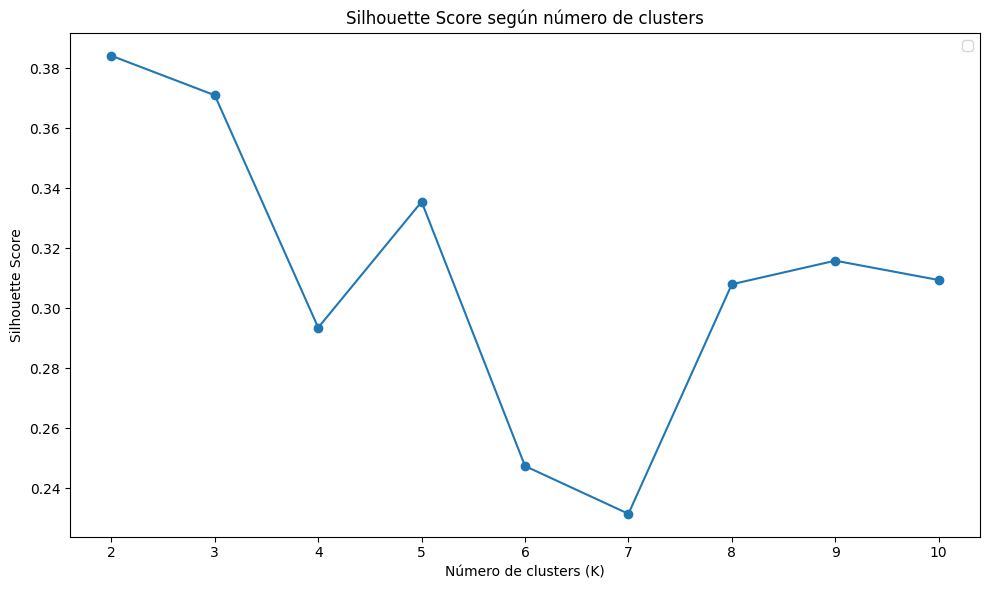

/tmp/ipykernel_2461/544393607.py:276: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


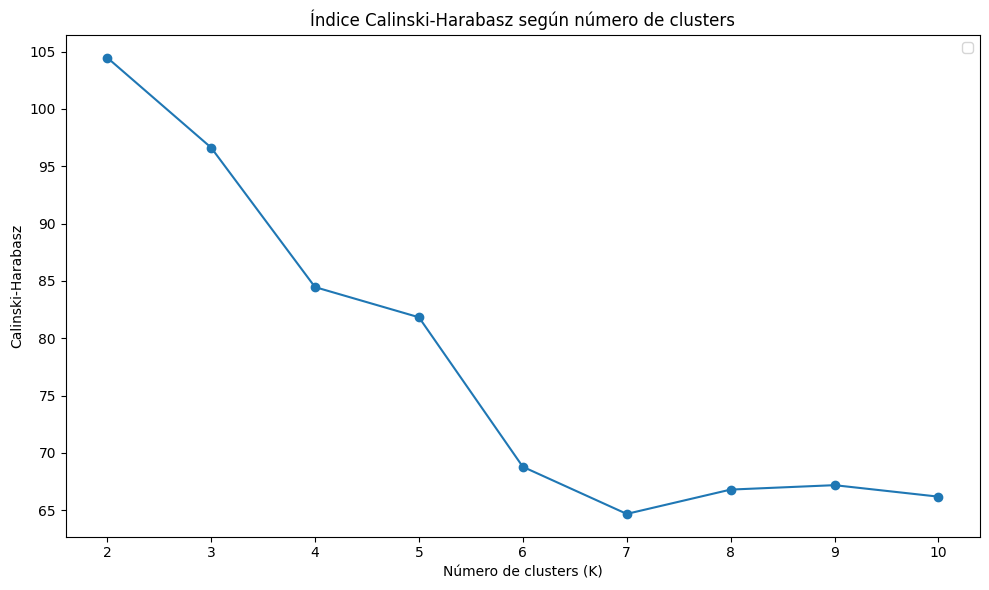

/tmp/ipykernel_2461/544393607.py:321: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


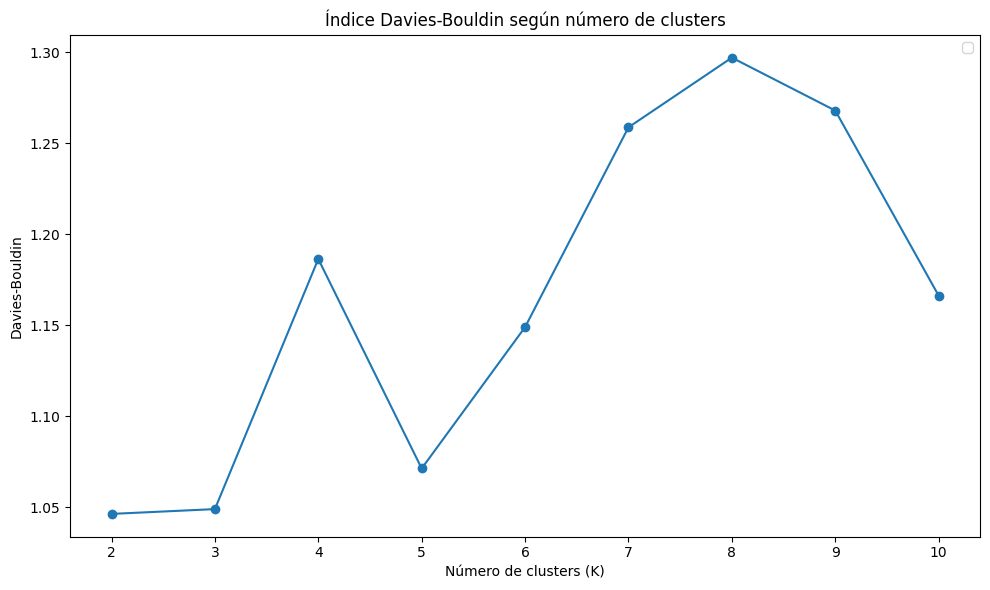


MÉTRICAS DEL MODELO FINAL
Silhouette Score: 0.2936
Calinski-Harabasz: 84.4563
Davies-Bouldin: 1.1864

TAMAÑO DE LOS CLUSTERS
         clientes  porcentaje
cluster                      
0              20       14.18
1              49       34.75
2              31       21.99
3              41       29.08

PERFIL DE LOS CLUSTERS
         venta_promedio_mensual  mix_cuidado_hogar  mix_abarrotes  \
cluster                                                             
0                     720094.06              98.90          40.29   
1                      56821.55               4.02           0.97   
2                     455798.06              84.26           5.53   
3                     219410.97              28.60           5.40   

         mix_golosinas  mix_cuidado_personal  frecuencia_promedio_compra  
cluster                                                                   
0                34.05                 21.90                       23.67  
1                11.24        

In [17]:
# ============================================================
# 2. CARGAR BASE
# ============================================================

df = base_clientes.copy()


# ============================================================
# 3. VARIABLES PARA LA SEGMENTACIÓN
# ============================================================

variables_cluster = [
    'venta_promedio_mensual',
    'mix_cuidado_hogar',
    'mix_abarrotes',
    'mix_golosinas',
    'mix_cuidado_personal',
    #'mix_panetones',
    'frecuencia_promedio_compra'
]

X = df[variables_cluster].copy()


# ============================================================
# 4. CONVERTIR A NUMÉRICO
# ============================================================

for col in variables_cluster:
    X[col] = pd.to_numeric(
        X[col],
        errors='coerce'
    )


# ============================================================
# 5. REEMPLAZAR INFINITOS
# ============================================================

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)


# ============================================================
# 6. ELIMINAR REGISTROS CON NULOS
# ============================================================

mask_validos = X.notnull().all(axis=1)

df_modelo = df.loc[mask_validos].copy()

X = X.loc[mask_validos].copy()


# ============================================================
# 7. ESTANDARIZACIÓN
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# ============================================================
# 8. EVALUACIÓN DEL NÚMERO DE CLUSTERS
# ============================================================

k_range = range(2, 11)

silhouette_scores = []
calinski_scores = []
davies_scores = []


for k in k_range:

    kmedoids_temp = KMedoids(
        n_clusters=k,
        metric='euclidean',
        method='alternate',
        init='k-medoids++',
        max_iter=300,
        random_state=42
    )

    clusters_temp = kmedoids_temp.fit_predict(X_scaled)

    # ----------------------------------------
    # Silhouette
    # ----------------------------------------

    silhouette = silhouette_score(
        X_scaled,
        clusters_temp
    )

    # ----------------------------------------
    # Calinski-Harabasz
    # ----------------------------------------

    calinski = calinski_harabasz_score(
        X_scaled,
        clusters_temp
    )

    # ----------------------------------------
    # Davies-Bouldin
    # ----------------------------------------

    davies = davies_bouldin_score(
        X_scaled,
        clusters_temp
    )

    silhouette_scores.append(silhouette)
    calinski_scores.append(calinski)
    davies_scores.append(davies)


# ============================================================
# 9. TABLA DE MÉTRICAS
# ============================================================

metricas_clusters = pd.DataFrame({
    'k': list(k_range),
    'silhouette': silhouette_scores,
    'calinski_harabasz': calinski_scores,
    'davies_bouldin': davies_scores
})


print("\n============================================================")
print("MÉTRICAS DE VALIDACIÓN")
print("============================================================")

print(
    metricas_clusters.round(4)
)


# ============================================================
# 10. MEJOR K SEGÚN CADA MÉTRICA
# ============================================================

mejor_k_silhouette = metricas_clusters.loc[
    metricas_clusters['silhouette'].idxmax(),
    'k'
]

mejor_k_calinski = metricas_clusters.loc[
    metricas_clusters['calinski_harabasz'].idxmax(),
    'k'
]

mejor_k_davies = metricas_clusters.loc[
    metricas_clusters['davies_bouldin'].idxmin(),
    'k'
]


print("\n============================================================")
print("MEJOR K SEGÚN CADA MÉTRICA")
print("============================================================")

print(
    "Mejor K según Silhouette:",
    mejor_k_silhouette
)

print(
    "Mejor K según Calinski-Harabasz:",
    mejor_k_calinski
)

print(
    "Mejor K según Davies-Bouldin:",
    mejor_k_davies
)


# ============================================================
# 11. K FINAL
# ============================================================

k_final = 4


print("\nK seleccionado para la segmentación:", k_final)


# ============================================================
# 12. GRÁFICO SILHOUETTE
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    list(k_range),
    silhouette_scores,
    marker='o'
)

#plt.axvline(
#    x=k_final,
#    linestyle='--',
#    label=f'K seleccionado = {k_final}'
#)

plt.title(
    'Silhouette Score según número de clusters'
)

plt.xlabel(
    'Número de clusters (K)'
)

plt.ylabel(
    'Silhouette Score'
)

plt.xticks(
    list(k_range)
)

#plt.grid(
#    alpha=0.3
#)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 13. GRÁFICO CALINSKI-HARABASZ
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    list(k_range),
    calinski_scores,
    marker='o'
)

#plt.axvline(
#    x=k_final,
#    linestyle='--',
#    label=f'K seleccionado = {k_final}'
#)

plt.title(
    'Índice Calinski-Harabasz según número de clusters'
)

plt.xlabel(
    'Número de clusters (K)'
)

plt.ylabel(
    'Calinski-Harabasz'
)

plt.xticks(
    list(k_range)
)

#plt.grid(
#    alpha=0.3
#)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 14. GRÁFICO DAVIES-BOULDIN
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    list(k_range),
    davies_scores,
    marker='o'
)

#plt.axvline(
#    x=k_final,
#    linestyle='--',
#    label=f'K seleccionado = {k_final}'
#)

plt.title(
    'Índice Davies-Bouldin según número de clusters'
)

plt.xlabel(
    'Número de clusters (K)'
)

plt.ylabel(
    'Davies-Bouldin'
)

plt.xticks(
    list(k_range)
)

#plt.grid(
#    alpha=0.3
#)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 15. K-MEDOIDS DEFINITIVO
# ============================================================

kmedoids = KMedoids(
    n_clusters=k_final,
    metric='euclidean',
    method='alternate',
    init='k-medoids++',
    max_iter=300,
    random_state=42
)

clusters = kmedoids.fit_predict(
    X_scaled
)


# ============================================================
# 16. ASIGNAR CLUSTER
# ============================================================

df_modelo['cluster'] = clusters


# ============================================================
# 17. MÉTRICAS DEL MODELO FINAL
# ============================================================

silhouette = silhouette_score(
    X_scaled,
    clusters
)

calinski = calinski_harabasz_score(
    X_scaled,
    clusters
)

davies = davies_bouldin_score(
    X_scaled,
    clusters
)


print("\n============================================================")
print("MÉTRICAS DEL MODELO FINAL")
print("============================================================")

print(
    "Silhouette Score:",
    round(silhouette, 4)
)

print(
    "Calinski-Harabasz:",
    round(calinski, 4)
)

print(
    "Davies-Bouldin:",
    round(davies, 4)
)


# ============================================================
# 18. CANTIDAD DE CLIENTES POR CLUSTER
# ============================================================

tamano_clusters = (
    df_modelo['cluster']
    .value_counts()
    .sort_index()
    .to_frame('clientes')
)

tamano_clusters['porcentaje'] = (
    tamano_clusters['clientes']
    / len(df_modelo)
    * 100
).round(2)


print("\n============================================================")
print("TAMAÑO DE LOS CLUSTERS")
print("============================================================")

print(
    tamano_clusters
)


# ============================================================
# 19. PERFIL DE LOS CLUSTERS
# ============================================================

perfil_clusters = (
    df_modelo
    .groupby('cluster')[variables_cluster]
    .mean()
    .round(2)
)


print("\n============================================================")
print("PERFIL DE LOS CLUSTERS")
print("============================================================")

print(
    perfil_clusters
)


# ============================================================
# 20. MEDOIDS
# ============================================================

indices_medoids = kmedoids.medoid_indices_

clientes_medoids = df_modelo.iloc[
    indices_medoids
].copy()


print("\n============================================================")
print("CLIENTES REPRESENTANTES DE CADA CLUSTER")
print("============================================================")

print(
    clientes_medoids[
        [
            'cod_cliente_alicorp_actual',
            'nom_cliente_alicorp_actual',
            'cluster'
        ]
    ]
)


# ============================================================
# 21. EXPORTAR CLIENTES SEGMENTADOS
# ============================================================

df_modelo.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/clientes_segmentados_kmedoids.xlsx",
    index=False
)


# ============================================================
# 22. EXPORTAR PERFIL
# ============================================================

perfil_clusters.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/perfil_clusters_kmedoids.xlsx"
)


# ============================================================
# 23. EXPORTAR MEDOIDS
# ============================================================

clientes_medoids.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/clientes_medoids.xlsx",
    index=False
)


# ============================================================
# 24. EXPORTAR MÉTRICAS
# ============================================================

metricas_clusters.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/metricas_kmedoids.xlsx",
    index=False
)


print("\n============================================================")
print("PROCESO TERMINADO")
print("============================================================")

## **CLUSTER JEARQUICO**

In [18]:
Z = base_clientes[variables_cluster].copy()
display(Z.head())

,venta_promedio_mensual,mix_cuidado_hogar,mix_abarrotes,mix_golosinas,mix_cuidado_personal,frecuencia_promedio_compra
25,29460.036667,2.500000,0.000000,0.000000,0.000000,10.500000
65,540640.997500,97.500000,43.500000,23.250000,22.916667,21.083333
89,784451.302500,104.250000,44.083333,39.333333,23.416667,23.000000
90,240621.300833,0.000000,0.000000,19.666667,0.000000,18.416667
117,191540.197500,3.222222,1.125000,29.416667,0.857143,16.416667


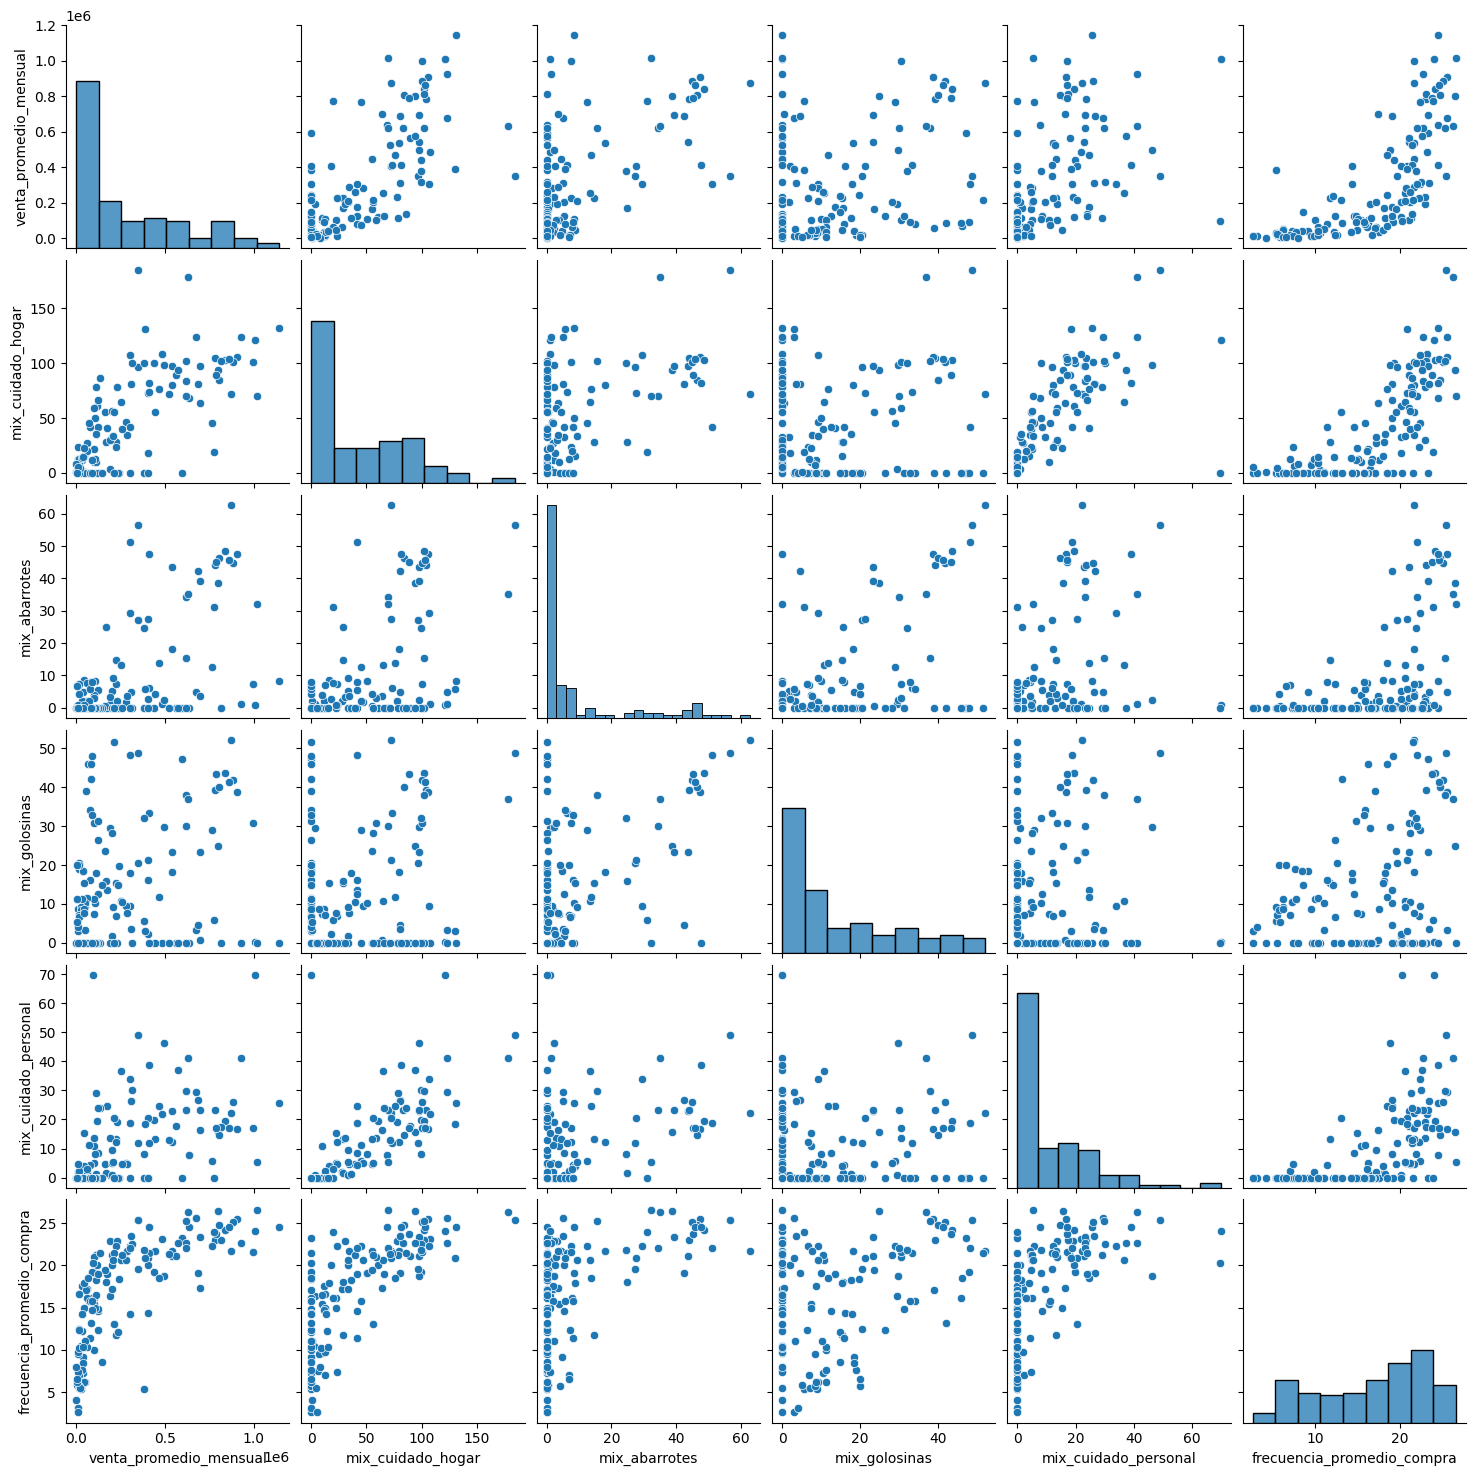

In [19]:
sns.pairplot(Z)

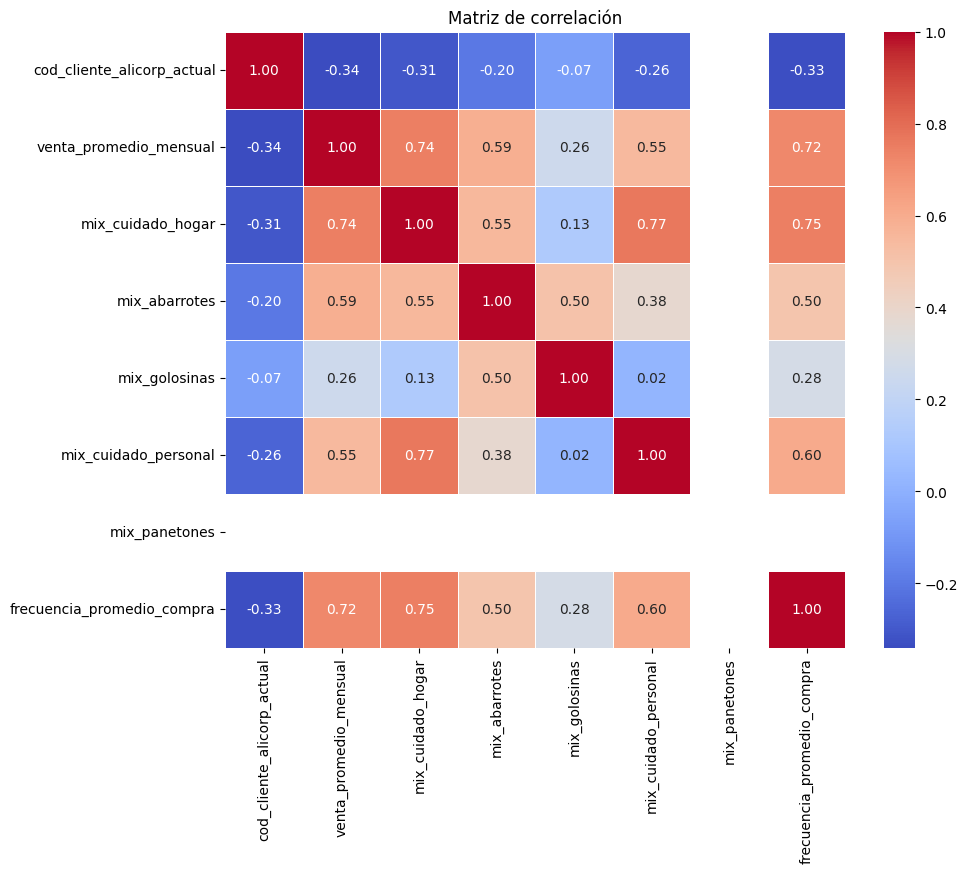

In [20]:
# Calcular la matriz de correlación
correlacion = base_clientes.corr(numeric_only=True)

# Generar el heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlacion,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Matriz de correlación')
plt.show()

In [21]:
for col in variables_cluster:

    Z[col] = pd.to_numeric(
        Z[col],
        errors='coerce'
    )

In [22]:
# ============================================================
# 5. REVISAR NULOS
# ============================================================

print(
    Z.isnull().sum()
)

venta_promedio_mensual        0
mix_cuidado_hogar             0
mix_abarrotes                 0
mix_golosinas                 0
mix_cuidado_personal          0
frecuencia_promedio_compra    0
dtype: int64


In [23]:
print(
    "Total de filas con algún nulo:",
    Z.isnull().any(axis=1).sum()
)

Total de filas con algún nulo: 0


In [24]:
# ============================================================
# 7. ESTADÍSTICOS DESCRIPTIVOS
# ============================================================

display(
    Z.describe().T
)

,count,mean,std,min,25%,50%,75%,max
venta_promedio_mensual,141.0,285898.768958,293306.383600,703.806667,44076.358333,172273.740000,444375.199167,1.144120e+06
mix_cuidado_hogar,141.0,42.264762,43.673051,0.000000,0.000000,28.428571,78.500000,1.844167e+02
mix_abarrotes,141.0,8.837723,15.357105,0.000000,0.000000,1.000000,8.000000,6.275000e+01
mix_golosinas,141.0,14.015786,15.258677,0.000000,0.000000,9.125000,23.250000,5.216667e+01
mix_cuidado_personal,141.0,10.761868,13.945552,0.000000,0.000000,4.666667,18.833333,6.983333e+01
frecuencia_promedio_compra,141.0,16.678414,6.449690,2.600000,11.400000,18.416667,21.666667,2.658333e+01


In [25]:
display(
    Z.quantile(
        [0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]
    ).T
)

,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
venta_promedio_mensual,703.806667,2742.035000,12082.715,44076.358333,172273.740000,444375.199167,875841.432500,1.014308e+06,1.144120e+06
mix_cuidado_hogar,0.000000,0.000000,0.000,0.000000,28.428571,78.500000,108.000000,1.595500e+02,1.844167e+02
mix_abarrotes,0.000000,0.000000,0.000,0.000000,1.000000,8.000000,45.750000,5.441667e+01,6.275000e+01
mix_golosinas,0.000000,0.000000,0.000,0.000000,9.125000,23.250000,45.916667,5.041667e+01,5.216667e+01
mix_cuidado_personal,0.000000,0.000000,0.000,0.000000,4.666667,18.833333,37.166667,6.140000e+01,6.983333e+01
frecuencia_promedio_compra,2.600000,2.833333,5.500,11.400000,18.416667,21.666667,25.083333,2.635000e+01,2.658333e+01


In [26]:
# ============================================================
# 8. ESTANDARIZACIÓN
# ============================================================

scaler = StandardScaler()

Z_scaled = scaler.fit_transform(Z)

Z_scaled = pd.DataFrame(
    Z_scaled,
    columns=variables_cluster,
    index=Z.index
)

display(
    Z_scaled.head()
)

,venta_promedio_mensual,mix_cuidado_hogar,mix_abarrotes,mix_golosinas,mix_cuidado_personal,frecuencia_promedio_compra
25,-0.877420,-0.913756,-0.577533,-0.921820,-0.774457,-0.961355
65,0.871616,1.269253,2.265131,0.607335,0.874697,0.685401
89,1.705827,1.424362,2.303251,1.665138,0.910678,0.983632
90,-0.154920,-0.971204,-0.577533,0.371659,-0.774457,0.270470
117,-0.322853,-0.897160,-0.504016,1.012918,-0.712775,-0.040728


In [27]:
# ============================================================
# 9. MATRIZ DE DISTANCIAS
# ============================================================

distancias = pdist(
    Z_scaled,
    metric='euclidean'
)

print(
    "Número de distancias:",
    len(distancias)
)

Número de distancias: 9870


In [28]:
# ============================================================
# 10. MÉTODOS DE LINKAGE
# ============================================================

metodos_linkage = [
    'ward',
    'complete',
    'average',
    'single'
]

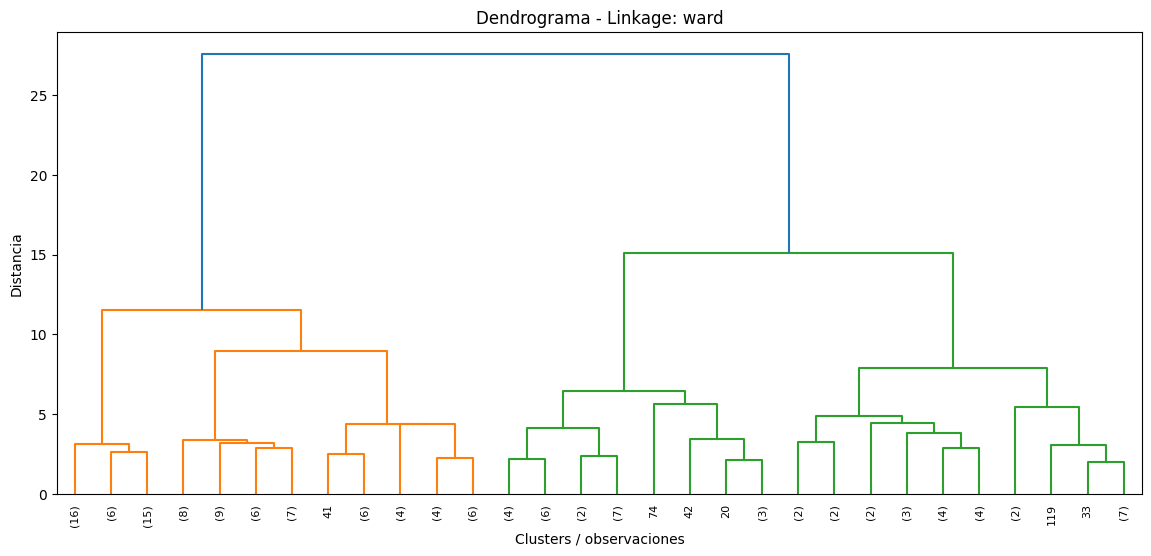

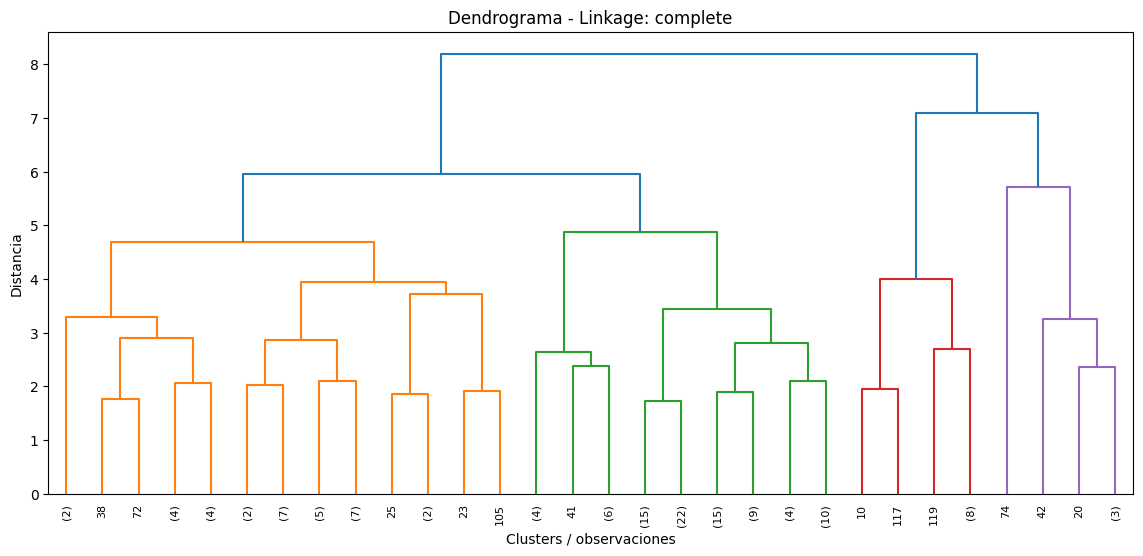

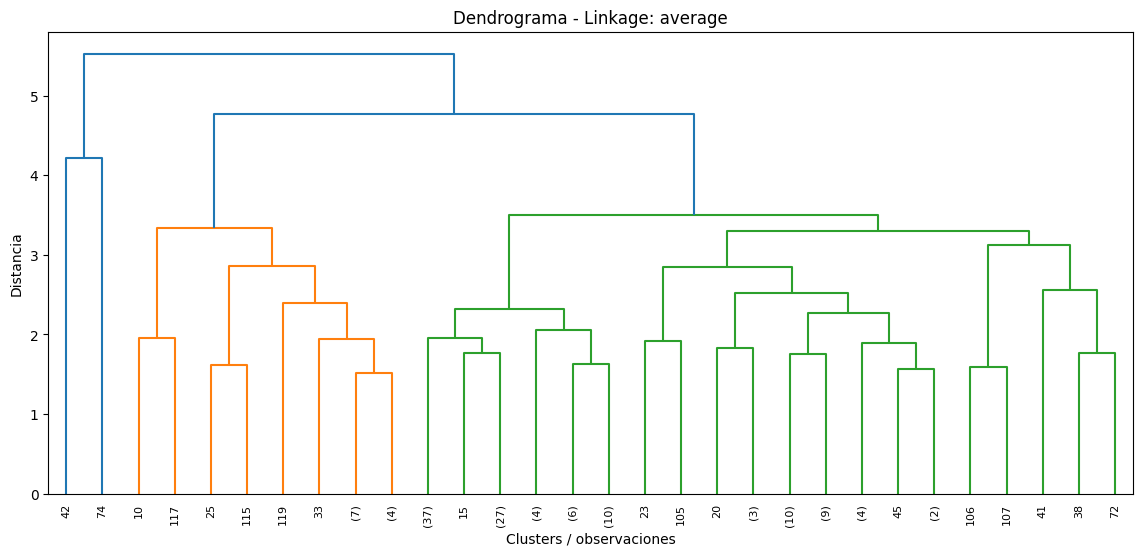

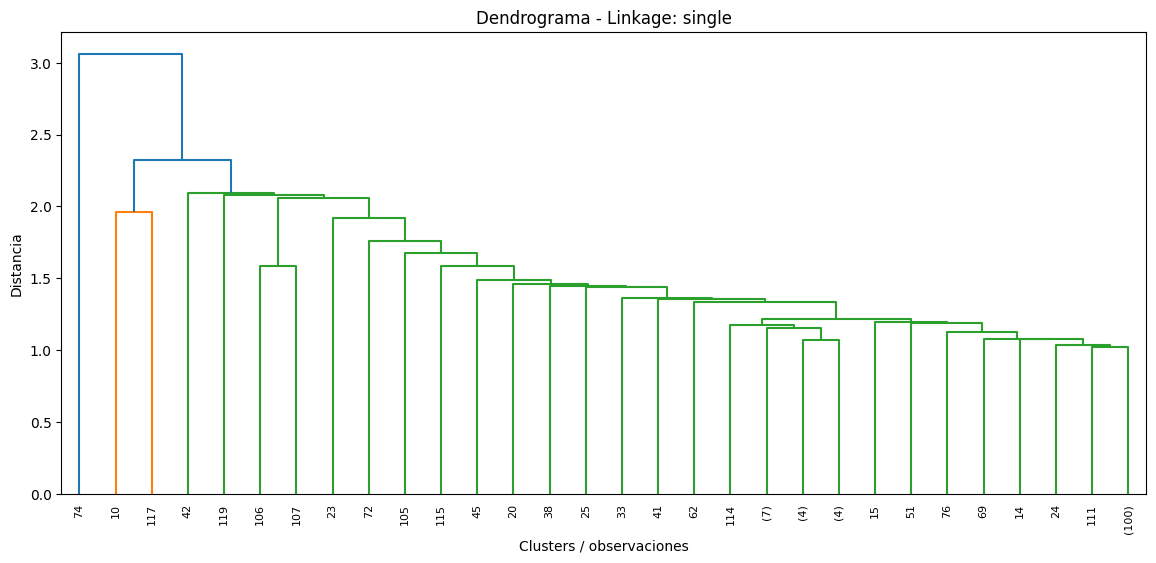

In [29]:
# ============================================================
# 11. DENDROGRAMAS
# ============================================================

for metodo in metodos_linkage:

    plt.figure(figsize=(14, 6))

    Z_L = linkage(
        Z_scaled,
        method=metodo,
        metric='euclidean'
    )

    dendrogram(
        Z_L,
        truncate_mode='lastp',
        p=30,
        leaf_rotation=90,
        leaf_font_size=8
    )

    plt.title(
        f'Dendrograma - Linkage: {metodo}'
    )

    plt.xlabel(
        'Clusters / observaciones'
    )

    plt.ylabel(
        'Distancia'
    )

    plt.show()

In [30]:
# ============================================================
# 12. EVALUACIÓN DE K Y LINKAGE
# ============================================================

resultados = []

for metodo in metodos_linkage:

    Z_L = linkage(
        Z_scaled,
        method=metodo,
        metric='euclidean'
    )

    for k in range(2, 11):

        clusters = fcluster(
            Z_L,
            t=k,
            criterion='maxclust'
        )

        silhouette = silhouette_score(
            Z_scaled,
            clusters
        )

        calinski = calinski_harabasz_score(
            Z_scaled,
            clusters
        )

        davies = davies_bouldin_score(
            Z_scaled,
            clusters
        )

        resultados.append({

            'linkage': metodo,

            'k': k,

            'silhouette': silhouette,

            'calinski_harabasz': calinski,

            'davies_bouldin': davies
        })


resultados = pd.DataFrame(
    resultados
)

display(resultados)

,linkage,k,silhouette,calinski_harabasz,davies_bouldin
0,ward,2,0.427141,113.270288,1.041570
1,ward,3,0.412145,96.618110,1.022081
2,ward,4,0.314138,89.548928,1.090146
3,ward,5,0.331930,83.133242,1.063949
4,ward,6,0.321511,79.437176,1.208944
5,ward,7,0.322726,75.219538,1.205293
6,ward,8,0.325695,71.412576,1.041024
7,ward,9,0.333337,69.128279,0.969353
8,ward,10,0.339705,67.016953,1.007548
9,complete,2,0.408499,46.539589,1.169103


In [31]:
# # Eliminar columna índice si existe
# if 'Unnamed: 0' in resultados.columns:
#     resultados = resultados.drop(columns=['Unnamed: 0'])


# # ============================================================
# # 2. ORDENAR RESULTADOS
# # ============================================================

# resultados = resultados.sort_values(
#     ['linkage', 'k']
# )


# # ============================================================
# # 3. OBTENER LINKAGES
# # ============================================================

# linkages = resultados['linkage'].unique()


# # ============================================================
# # 4. GRÁFICO SILHOUETTE
# # ============================================================

# plt.figure(figsize=(10, 6))

# for linkage in linkages:

#     datos = resultados[
#         resultados['linkage'] == linkage
#     ]

#     plt.plot(
#         datos['k'],
#         datos['silhouette'],
#         marker='o',
#         linewidth=2,
#         label=linkage
#     )


# plt.title(
#     'Silhouette Score según número de clusters y linkage'
# )

# plt.xlabel(
#     'Número de clusters (K)'
# )

# plt.ylabel(
#     'Silhouette Score'
# )

# plt.xticks(
#     sorted(resultados['k'].unique())
# )

# #plt.grid(
# #    alpha=0.3
# #)

# plt.legend(
#     title='Linkage'
# )

# plt.tight_layout()

# plt.show()


# # ============================================================
# # 5. GRÁFICO CALINSKI-HARABASZ
# # ============================================================

# plt.figure(figsize=(10, 6))

# for linkage in linkages:

#     datos = resultados[
#         resultados['linkage'] == linkage
#     ]

#     plt.plot(
#         datos['k'],
#         datos['calinski_harabasz'],
#         marker='o',
#         linewidth=2,
#         label=linkage
#     )


# plt.title(
#     'Índice Calinski-Harabasz según número de clusters y linkage'
# )

# plt.xlabel(
#     'Número de clusters (K)'
# )

# plt.ylabel(
#     'Calinski-Harabasz'
# )

# plt.xticks(
#     sorted(resultados['k'].unique())
# )

# #plt.grid(
# #    alpha=0.3
# #)

# plt.legend(
#     title='Linkage'
# )

# plt.tight_layout()

# plt.show()


# # ============================================================
# # 6. GRÁFICO DAVIES-BOULDIN
# # ============================================================

# plt.figure(figsize=(10, 6))

# for linkage in linkages:

#     datos = resultados[
#         resultados['linkage'] == linkage
#     ]

#     plt.plot(
#         datos['k'],
#         datos['davies_bouldin'],
#         marker='o',
#         linewidth=2,
#         label=linkage
#     )


# plt.title(
#     'Índice Davies-Bouldin según número de clusters y linkage'
# )

# plt.xlabel(
#     'Número de clusters (K)'
# )

# plt.ylabel(
#     'Davies-Bouldin'
# )

# plt.xticks(
#     sorted(resultados['k'].unique())
# )

# #plt.grid(
# #    alpha=0.3
# #)

# plt.legend(
#     title='Linkage'
# )

# plt.tight_layout()

# plt.show()

In [32]:
## Silouette

display(
    resultados
    .sort_values(
        'silhouette',
        ascending=False
    )
    .head(10)
)

,linkage,k,silhouette,calinski_harabasz,davies_bouldin
19,average,3,0.430172,38.468484,0.813690
18,average,2,0.429737,7.332583,0.931467
0,ward,2,0.427141,113.270288,1.041570
1,ward,3,0.412145,96.618110,1.022081
9,complete,2,0.408499,46.539589,1.169103
20,average,4,0.405851,26.646545,0.574927
27,single,2,0.393372,3.532280,0.486459
21,average,5,0.386512,54.801522,0.772176
22,average,6,0.383164,46.979612,0.760335
23,average,7,0.382967,44.232325,0.882813


In [33]:
## Calinski-Harabasz

display(
    resultados
    .sort_values(
        'calinski_harabasz',
        ascending=False
    )
    .head(10)
)

,linkage,k,silhouette,calinski_harabasz,davies_bouldin
0,ward,2,0.427141,113.270288,1.041570
1,ward,3,0.412145,96.618110,1.022081
2,ward,4,0.314138,89.548928,1.090146
3,ward,5,0.331930,83.133242,1.063949
4,ward,6,0.321511,79.437176,1.208944
5,ward,7,0.322726,75.219538,1.205293
6,ward,8,0.325695,71.412576,1.041024
7,ward,9,0.333337,69.128279,0.969353
8,ward,10,0.339705,67.016953,1.007548
11,complete,4,0.365044,66.809352,1.275479


In [34]:
## Davies-Bouldin

display(
    resultados
    .sort_values(
        'davies_bouldin',
        ascending=True
    )
    .head(10)
)

,linkage,k,silhouette,calinski_harabasz,davies_bouldin
27,single,2,0.393372,3.532280,0.486459
29,single,4,0.331497,6.773484,0.500790
30,single,5,0.253278,5.814604,0.510039
28,single,3,0.340942,7.050716,0.547366
20,average,4,0.405851,26.646545,0.574927
32,single,7,0.177855,4.606058,0.575541
33,single,8,0.148369,4.280976,0.579628
34,single,9,0.140053,4.032227,0.582013
35,single,10,0.136204,3.847663,0.582078
31,single,6,0.188101,5.479591,0.636996


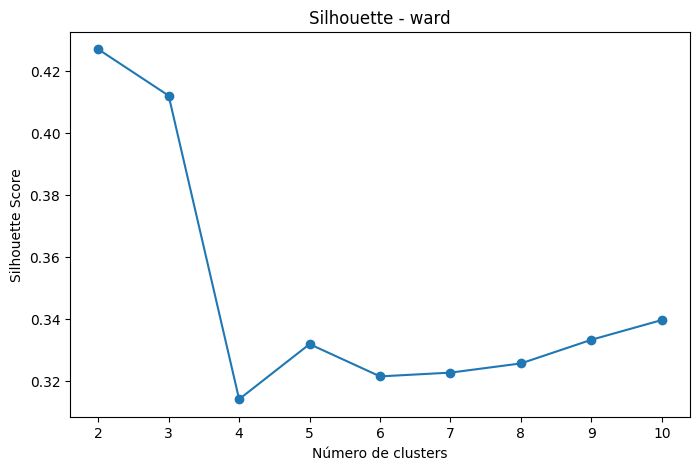

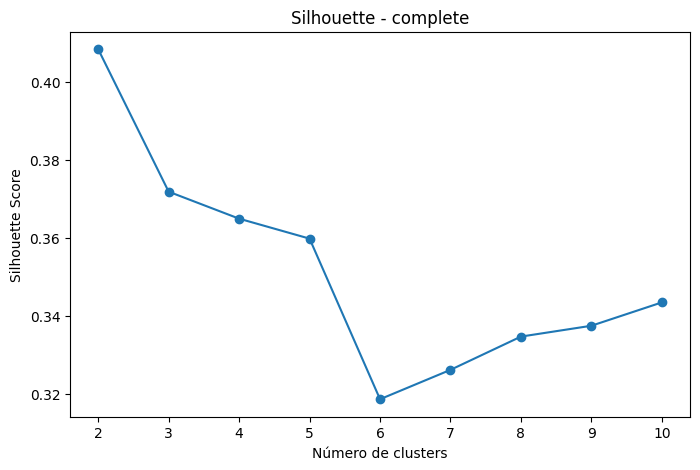

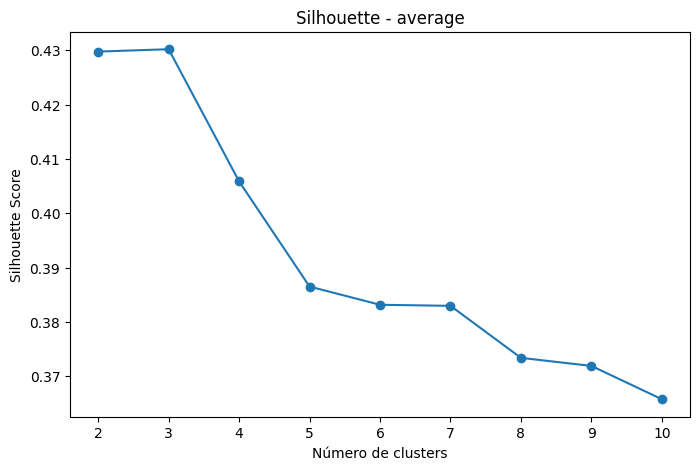

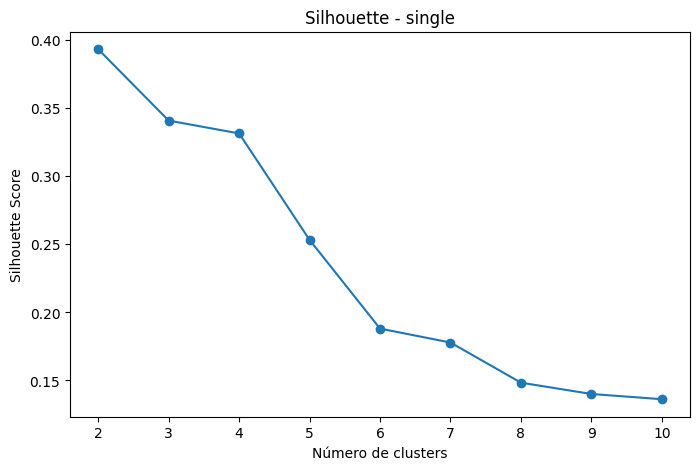

In [35]:
# ============================================================
# 13. SILHOUETTE POR K
# ============================================================

for metodo in metodos_linkage:

    datos = resultados[
        resultados['linkage'] == metodo
    ]

    plt.figure(figsize=(8, 5))

    plt.plot(
        datos['k'],
        datos['silhouette'],
        marker='o'
    )

    plt.xlabel(
        'Número de clusters'
    )

    plt.ylabel(
        'Silhouette Score'
    )

    plt.title(
        f'Silhouette - {metodo}'
    )

    plt.xticks(
        range(2, 11)
    )

    plt.show()

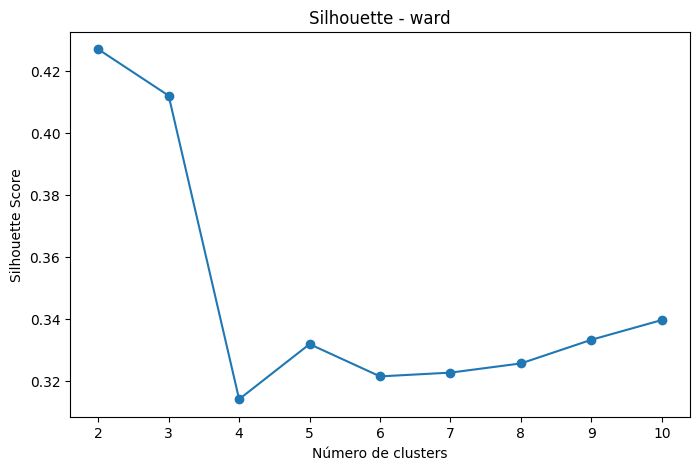

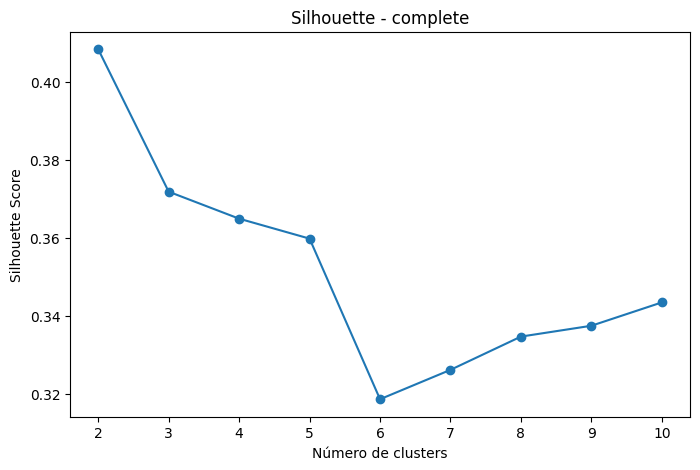

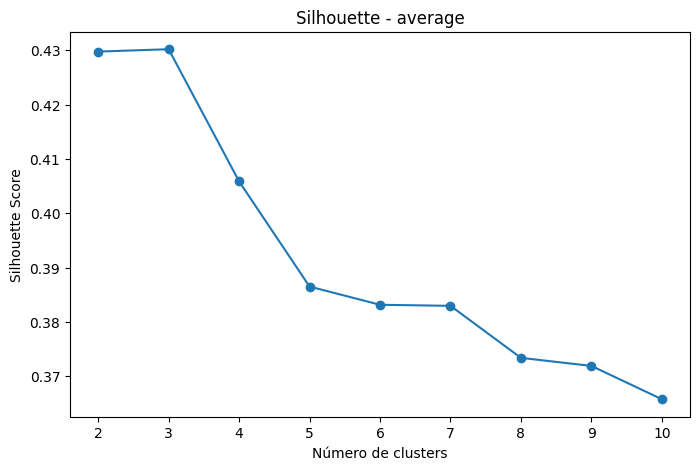

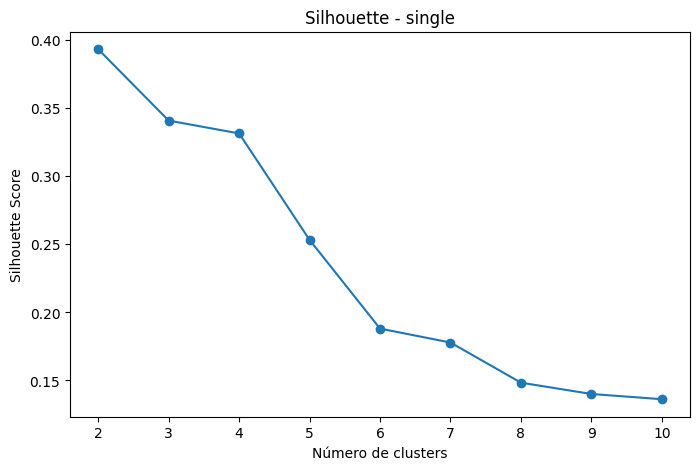

In [36]:
# ============================================================
# 13. SILHOUETTE POR K
# ============================================================

for metodo in metodos_linkage:

    datos = resultados[
        resultados['linkage'] == metodo
    ]

    plt.figure(figsize=(8, 5))

    plt.plot(
        datos['k'],
        datos['silhouette'],
        marker='o'
    )

    plt.xlabel(
        'Número de clusters'
    )

    plt.ylabel(
        'Silhouette Score'
    )

    plt.title(
        f'Silhouette - {metodo}'
    )

    plt.xticks(
        range(2, 11)
    )

    plt.show()

In [37]:
k_final = 4
metodo_final = 'ward'

In [38]:
# ============================================================
# 15. MODELO FINAL
# ============================================================

Z_final = linkage(
    Z_scaled,
    method=metodo_final,
    metric='euclidean'
)

clusters_final = fcluster(
    Z_final,
    t=k_final,
    criterion='maxclust'
)

In [39]:
# ============================================================
# 16. ASIGNAR CLUSTERS
# ============================================================

df_modelo['cluster'] = clusters_final

display(
    df_modelo.head()
)

,cod_cliente_alicorp_actual,nom_cliente_alicorp_actual,cod_grupo_precio_alicorp,venta_promedio_mensual,mix_cuidado_hogar,mix_abarrotes,mix_golosinas,mix_cuidado_personal,mix_panetones,frecuencia_promedio_compra,cluster
25,1000000433,INVERSIONES PUCARA S.A.C,D4,29460.036667,2.500000,0.000000,0.000000,0.000000,0,10.500000,1
65,1000002120,CONSORCIO LIDERCLOUD S.R.L.,D4,540640.997500,97.500000,43.500000,23.250000,22.916667,0,21.083333,4
89,1000004065,DACIA TRADING SAC,D4,784451.302500,104.250000,44.083333,39.333333,23.416667,0,23.000000,4
90,1000004071,COMERC.Y DISTRIBUID RACSER S.A.,D4,240621.300833,0.000000,0.000000,19.666667,0.000000,0,18.416667,2
117,1000007530,DISTRIBUIDORA CASTRO E.I.R.L.,D4,191540.197500,3.222222,1.125000,29.416667,0.857143,0,16.416667,2


In [40]:
# ============================================================
# 17. TAMAÑO DE SEGMENTOS
# ============================================================

tamano_clusters = (
    df_modelo['cluster']
    .value_counts()
    .sort_index()
    .to_frame(
        'clientes'
    )
)

tamano_clusters['porcentaje'] = (
    tamano_clusters['clientes']
    / len(df_modelo)
    * 100
).round(2)

display(
    tamano_clusters
)

,clientes,porcentaje
cluster,,
1,37,26.24
2,51,36.17
3,25,17.73
4,28,19.86


In [41]:
# ============================================================
# 18. PERFIL DE SEGMENTOS
# ============================================================

perfil_clusters = (
    df_modelo
    .groupby('cluster')[variables_cluster]
    .agg([
        'mean',
        'median'
    ])
    .round(2)
)

display(
    perfil_clusters
)

venta_promedio_mensual            mix_cuidado_hogar         \
                          mean     median              mean median   
cluster                                                              
1                     39392.89   19356.53              3.51   0.00   
2                    162419.84  125076.09             21.49  17.92   
3                    485035.77  469188.11             86.27  83.50   
4                    658745.83  692193.38             92.04  97.04   

        mix_abarrotes        mix_golosinas        mix_cuidado_personal         \
                 mean median          mean median                 mean median   
cluster                                                                         
1                0.91   0.00          7.10   7.00                 0.24   0.00   
2                2.87   0.00         16.98  14.83                 4.40   1.08   
3                2.58   0.00          1.32   0.00                27.06  23.92   
4               35.77  38.96         29.10  30.29                21.69  19.92   

        frecuencia_promedio_compra         
                              mean median  
cluster                                    
1                             7.62   7.50  
2                            17.23  17.08  
3                            21.76  21.67  
4                            23.12  23.17

In [42]:
perfil_promedio = (
    df_modelo
    .groupby('cluster')[variables_cluster]
    .mean()
    .round(2)
)

display(
    perfil_promedio
)

,venta_promedio_mensual,mix_cuidado_hogar,mix_abarrotes,mix_golosinas,mix_cuidado_personal,frecuencia_promedio_compra
cluster,,,,,,
1,39392.89,3.51,0.91,7.10,0.24,7.62
2,162419.84,21.49,2.87,16.98,4.40,17.23
3,485035.77,86.27,2.58,1.32,27.06,21.76
4,658745.83,92.04,35.77,29.10,21.69,23.12


In [43]:
# ============================================================
# 19. ÍNDICE VS PROMEDIO GENERAL
# ============================================================

promedio_general = (
    df_modelo[variables_cluster]
    .mean()
)

indice_cluster = (
    perfil_promedio
    / promedio_general
    * 100
).round(1)

display(
    indice_cluster
)

,venta_promedio_mensual,mix_cuidado_hogar,mix_abarrotes,mix_golosinas,mix_cuidado_personal,frecuencia_promedio_compra
cluster,,,,,,
1,13.8,8.3,10.3,50.7,2.2,45.7
2,56.8,50.8,32.5,121.1,40.9,103.3
3,169.7,204.1,29.2,9.4,251.4,130.5
4,230.4,217.8,404.7,207.6,201.5,138.6


In [44]:
# ============================================================
# 20. EXPORTAR RESULTADOS
# ============================================================

df_modelo.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/clientes_clustering_jerarquico.xlsx",
    index=False
)

perfil_promedio.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/perfil_clusters_jerarquico.xlsx"
)

indice_cluster.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/indice_clusters_jerarquico.xlsx"
)

resultados.to_excel(
    "/content/drive/MyDrive/UNI/Proyecto de tesis 2/Sustentacion/outputs/evaluacion_clustering_jerarquico.xlsx",
    index=False
)

print(
    "Archivos exportados correctamente."
)

Archivos exportados correctamente.


## REVISAR PREPROCESAMIENTO (EXCLUSION DE OUTLIERS Y EVALUACION POSTERIOR)
## CORRER KMEDOIDS ()
